This notebook contains code on collecting NDVI from Sentinel-2 for the generated grids and then calculating the NDVI value for each 100m x 100m grid. The developed code relies on google earth engine for processing and google cloud for intermediate storage of data. One can look into STAC APIs for alternate way of processing.

In [1]:
import ee
import geopandas as gpd
import time
import rasterio
from rasterio.windows import from_bounds
import os
import numpy as np
import logging
from multiprocess import Pool
import glob
from functools import partial
from shapely.geometry import box

/home/trpb2/.conda/envs/geo_env/lib/python3.10/site-packages/google/api_core/_python_version_support.py:223: FutureWarning: You are using a non-supported Python version (3.10.22). Google will not post any further updates to google.api_core supporting this Python version. Please upgrade to the latest Python version, or at least Python 3.11, and then update google.api_core.
  warnings.warn(message, FutureWarning)


### data collection

In [8]:
# function to mask clouds in Sentinel-2 images using the Scene Classification Layer (SCL)
def maskS2CloudsUsingSCL(image):
    scl = image.select('SCL')
    cloud_mask = scl.gt(6).Or(scl.lt(4))  # Clouds are typically classified as values <4 or >6
    return image.updateMask(cloud_mask.Not()).divide(10000)  # Apply mask and scale reflectance

# function to add an NDVI band to a Sentinel-2 image
def addNDVI(image):
    ndvi = image.normalizedDifference(['B8', 'B4']).rename('NDVI')  # B8 (NIR) and B4 (Red)
    return image.addBands(ndvi)

# function to calculate the first quartile of an image collection
def firstQuartile(imageCollection):
    return imageCollection.reduce(ee.Reducer.percentile([25]))  # Compute the 25th percentile

# convert a Shapely Polygon to an Earth Engine Geometry Polygon
def shapely_to_ee_polygon(shapely_geom):
    exterior_coords = list(shapely_geom.exterior.coords)
    return ee.Geometry.Polygon(exterior_coords)

# function to manage Earth Engine task submission, ensuring task queue does not overflow
def wait_for_slots(max_tasks=2000, check_interval=60):
    while True:
        tasks = ee.data.getTaskList()
        running_or_ready_tasks = [task for task in tasks if task['state'] in ('RUNNING', 'READY')]
        if len(running_or_ready_tasks) < max_tasks:
            break
        else:
            print(f"Queue full with {len(running_or_ready_tasks)} tasks. Waiting...")
            time.sleep(check_interval)

In [30]:
# authenticate and initialize the Earth Engine session
ee.Authenticate()
ee.Initialize()

# load and reproject the 100km x 100km grid
eu_gdf = gpd.read_file('data/grid_100km_surf.gpkg')
eu_4326 = eu_gdf.to_crs('epsg:4326')

/home/trpb2/.conda/envs/geo_env/lib/python3.10/site-packages/pyogrio/raw.py:198: RuntimeWarning: GPKG: unrecognized user_version=0x00000000 (0) on 'data/grid_100km_surf.gpkg'
  return ogr_read(


In [5]:
print(len(eu_gdf), eu_gdf.crs)

1025 EPSG:3035


In [6]:
uk = eu_gdf[eu_gdf['CNTR_ID'] == 'UK']
uk_ids = (uk.index + 1).tolist()   # assumes a default RangeIndex
print(len(uk_ids), uk_ids[:10])

52 [529, 530, 565, 566, 567, 568, 569, 570, 603, 604]


In [8]:
eu_4326.iloc[607]

DIST_BORD                                          188667.71875
TOT_P_2018                                            9710710.0
TOT_P_2006                                            8385352.0
GRD_ID                        CRS3035RES100000mN3200000E3600000
TOT_P_2011                                            9028992.0
TOT_P_2021                                                    0
Y_LLC                                                   3200000
CNTR_ID                                                      UK
NUTS2016_3    UKF25-UKH12-UKH14-UKH17-UKH21-UKH23-UKH24-UKH2...
NUTS2016_2              UKF2-UKH1-UKH2-UKH3-UKI3-UKI4-UKI5-UKI7
NUTS2016_1                                          UKF-UKH-UKI
NUTS2016_0                                                   UK
LAND_PC                                               97.610001
X_LLC                                                   3600000
NUTS2021_3    UKF25-UKH12-UKH14-UKH17-UKH21-UKH23-UKH24-UKH2...
NUTS2021_2              UKF2-UKH1-UKH2-U

In [36]:
row = eu_4326.iloc[607]
geometry = shapely_to_ee_polygon(row.geometry)
dataset = (ee.ImageCollection('COPERNICUS/S2_SR_HARMONIZED')
           .filterDate('2018-06-01', '2018-06-15')
           .filter(ee.Filter.lt('CLOUDY_PIXEL_PERCENTAGE', 20))
           .filterBounds(geometry)
           .map(maskS2CloudsUsingSCL)
           .map(addNDVI))

In [10]:
tile_geom_3035 = eu_gdf.iloc[607].geometry
center = tile_geom_3035.centroid
test_geom_3035 = box(
    center.x - 500,
    center.y - 500,
    center.x + 500,
    center.y + 500,
)

In [11]:
# Earth Engine coordinates must be longitude/latitude.
test_geom_4326 = gpd.GeoSeries(
    [test_geom_3035],
    crs="EPSG:3035",
).to_crs("EPSG:4326").iloc[0]
test_geometry = shapely_to_ee_polygon(test_geom_4326)


In [12]:
dataset = (ee.ImageCollection('COPERNICUS/S2_SR_HARMONIZED')
           .filterDate('2018-06-01', '2018-09-30')
           .filter(ee.Filter.lt('CLOUDY_PIXEL_PERCENTAGE', 20))
           .filterBounds(test_geometry)
           .map(maskS2CloudsUsingSCL)
           .map(addNDVI))

In [37]:
print("images:", dataset.size().getInfo())
print("Bands:", dataset.first().bandNames().getInfo())

images: 7
Bands: ['B1', 'B2', 'B3', 'B4', 'B5', 'B6', 'B7', 'B8', 'B8A', 'B9', 'B11', 'B12', 'AOT', 'WVP', 'SCL', 'TCI_R', 'TCI_G', 'TCI_B', 'MSK_CLDPRB', 'MSK_SNWPRB', 'QA10', 'QA20', 'QA60', 'MSK_CLASSI_OPAQUE', 'MSK_CLASSI_CIRRUS', 'MSK_CLASSI_SNOW_ICE', 'NDVI']


In [38]:
        firstQuartileComposite = firstQuartile(dataset)
        medianFiltered = firstQuartileComposite.focal_median(1000, 'circle', 'meters')
        filledComposite = firstQuartileComposite.unmask(medianFiltered).select(['NDVI_p25'])

In [39]:
        task = ee.batch.Export.image.toDrive(
            image=filledComposite,
            description=f"NDVI_100m_607_15daysjune",
            folder='walkability_uk_slope',     # Google Drive folder name
            fileNamePrefix=f"eu_ndvi/NDVI_100m_607_15daysjune",
            scale=100,
            region=geometry,
            crs='EPSG:3035',
            fileFormat='GeoTIFF',
            formatOptions={'cloudOptimized': True},
            maxPixels=1e13
        )
        
        task.start()

In [6]:
# process each row in the reprojected geodataframe
# in the original code i started from 1 and it had i+1 as the condition
# the issue is the the EU 100km grid is a 0 based index and Nishit has a 1 based index
#  it seems like a better idea to have i refer to the 100km grid and add one when writing the file

for i, row in enumerate(eu_4326.itertuples()):
    # grid 611 condition (in order to not process everything)
    #if i+1 == 611:
    if i == 607:
        geometry = shapely_to_ee_polygon(row.geometry)
        dataset = (ee.ImageCollection('COPERNICUS/S2_SR_HARMONIZED')
                   .filterDate('2018-03-01', '2018-09-30')
                   .filter(ee.Filter.lt('CLOUDY_PIXEL_PERCENTAGE', 20))
                   .filterBounds(geometry)
                   .map(maskS2CloudsUsingSCL)
                   .map(addNDVI))
    
        if dataset.size().getInfo() == 0:
            print(f"No images found for index {i}, skipping...")
            continue
    
        firstQuartileComposite = firstQuartile(dataset)
        medianFiltered = firstQuartileComposite.focal_median(1000, 'circle', 'meters')
        filledComposite = firstQuartileComposite.unmask(medianFiltered).select(['NDVI_p25'])
    
#         exportParams = {
#             'image': filledComposite,
#             'description': f"NDVI_10m_{i}",
#             'bucket': 'cog-bucket-test',    # your bucket name
#             'fileNamePrefix': f"eu_ndvi/NDVI_10m_{i}",
#             'scale': 10,
#             'region': geometry,
#             'crs': 'EPSG:3035',
#             'fileFormat': 'GeoTIFF',
#             'formatOptions': {'cloudOptimized': True},
#             'maxPixels': 1e13
#         }
        
#         task = ee.batch.Export.image.toCloudStorage(**exportParams)
        
        task = ee.batch.Export.image.toDrive(
            image=filledComposite,
            description=f"NDVI_10m_{i+1}",
            folder='walkability_uk_slope',     # Google Drive folder name
            fileNamePrefix=f"eu_ndvi/NDVI_10m_{i+1}",
            scale=10,
            region=geometry,
            crs='EPSG:3035',
            fileFormat='GeoTIFF',
            formatOptions={'cloudOptimized': True},
            maxPixels=1e13
        )
        
        task.start()

You can monitor the progress on your associated account at https://code.earthengine.google.com/. Once the images are completed processing and stored on your googlecloud, you can move to the next part of the code.

### calculate NDVI for 100mx100m grids

In [2]:
# set the environment variable for Google Cloud credentials
os.environ['GOOGLE_APPLICATION_CREDENTIALS'] = 'path/to/your/credentials.json'

# list to hold the paths of the parquet files
grids_list = []
for parquet_file in glob.glob('data/*.parquet'):
    grids_list.append(parquet_file)

# # configure logging (recommended if you monitor processing over a lot of files)
# log_path = 'logs/green_spaces.log'

# # ensure log directory exists
# log_dir = os.path.dirname(log_path)
# if not os.path.exists(log_dir):
#     os.makedirs(log_dir)
    
# logging.basicConfig(filename=log_path, level=logging.INFO,
#                     format='%(asctime)s:%(levelname)s:%(message)s', force=True)

In [7]:
def calculate_ndvi_row(row, src):
    """
    Calculate the NDVI mean for a single row (geometry) of a GeoDataFrame.

    Parameters:
    - row: A single row from GeoDataFrame.
    - src: Raster source object to read data from.

    Returns:
    - float: The mean NDVI value for the geometry in the row.
    """
    window = from_bounds(*row.geometry.bounds, transform=src.transform)
    data = src.read(window=window)
    img = data[0]
    return np.nanmean(img)

def process_grid(grid_path):
    """
    Process each grid to calculate NDVI and save the results back to a parquet file.

    Parameters:
    - grid_path: The file path to the grid parquet file.
    """
    try:
        grid_number = grid_path.split('_')[-1].split('.')[0]
        grid_gdf = gpd.read_parquet(grid_path)

        if 'ndvi' in grid_gdf.columns:
            logging.info(f'Skipping grid {grid_number} as NDVI already calculated')
            return

        #cog_path = f'gs://cog-bucket-test/eu_ndvi/NDVI_10m_{grid_number}.tif'
        cog_path = f'data/ndvi/eu_ndvi_NDVI_100m_{grid_number}.tif'
        # logging.info(f'Started processing grid {grid_number} and {cog_path}')
        print(f'Started processing grid {grid_number} and {cog_path}')
        
        with rasterio.open(cog_path) as src:
            if grid_gdf.crs != src.crs:
                grid_gdf = grid_gdf.to_crs(src.crs)

            calculate_with_src = partial(calculate_ndvi_row, src=src)
            grid_gdf['ndvi'] = grid_gdf.apply(lambda row: calculate_with_src(row), axis=1)

        grid_gdf.to_parquet(grid_path)
        # logging.info(f'Successfully processed grid {grid_path}')
        print(f'Successfully processed grid {grid_path}')
    except Exception as e:
        # logging.error(f'Error processing grid {grid_path}: {e}')
        print(f'Error processing grid {grid_path}: {e}')

In [9]:
# sequential
for elem in grids_list:
    process_grid(elem)

# # configure the number of parallel processes
# num_processes = 10 

# # create a pool of workers to process grids in parallel
# with Pool(processes=num_processes) as pool:
#     pool.map(process_grid, grids_list)

Started processing grid 608 and data/ndvi/eu_ndvi_NDVI_100m_608.tif
Successfully processed grid data/grids_100_608.parquet


In [4]:
grid_path = grids_list[0]


grid_number = grid_path.split('_')[-1].split('.')[0]
grid_gdf = gpd.read_parquet(grid_path)

In [19]:
import numpy as np
import rasterio
from rasterio.warp import reproject, Resampling
import matplotlib.pyplot as plt
from pathlib import Path

In [40]:
# ---- config: edit these ----
folder = Path("data/ndvi")
path_10m = folder / "eu_ndvi_NDVI_10m_607_15daysjune.tif"
path_100m = folder / "eu_ndvi_NDVI_100m_607_15daysjune.tif"

In [41]:
# ---- load the 100 m raster (the reference grid) ----
with rasterio.open(path_100m) as ref:
    ref_arr = ref.read(1).astype("float64")
    ref_nodata = ref.nodata
    ref_transform, ref_crs, ref_shape = ref.transform, ref.crs, ref.shape
    print("100m:", ref.crs, ref.res, ref.shape, "nodata:", ref.nodata)

if ref_nodata is not None:
    ref_arr[ref_arr == ref_nodata] = np.nan

100m: EPSG:3035 (100.0, 100.0) (1001, 1001) nodata: None


In [42]:
# ---- load the 10 m raster, aggregating it onto the 100 m grid ----
with rasterio.open(path_10m) as src:
    print("10m: ", src.crs, src.res, src.shape, "nodata:", src.nodata)
    src_arr = src.read(1).astype("float64")
    if src.nodata is not None:
        src_arr[src_arr == src.nodata] = np.nan

    agg_10m = np.full(ref_shape, np.nan, dtype="float64")
    reproject(
        source=src_arr,
        destination=agg_10m,
        src_transform=src.transform,
        src_crs=src.crs,
        src_nodata=np.nan,
        dst_transform=ref_transform,
        dst_crs=ref_crs,
        dst_nodata=np.nan,
        resampling=Resampling.average,  # mean of the 10m pixels in each 100m cell
    )

10m:  EPSG:3035 (10.0, 10.0) (10001, 10003) nodata: None



Valid pixels compared: 1,002,001 of 1,002,001
Mean NDVI  10m-agg: 0.6951 | 100m: 0.6891
Mean diff (100m - 10m agg): -0.0061
MAE:  0.0321
RMSE: 0.0577
Pearson r: 0.9709
95th pct |diff|: 0.1223


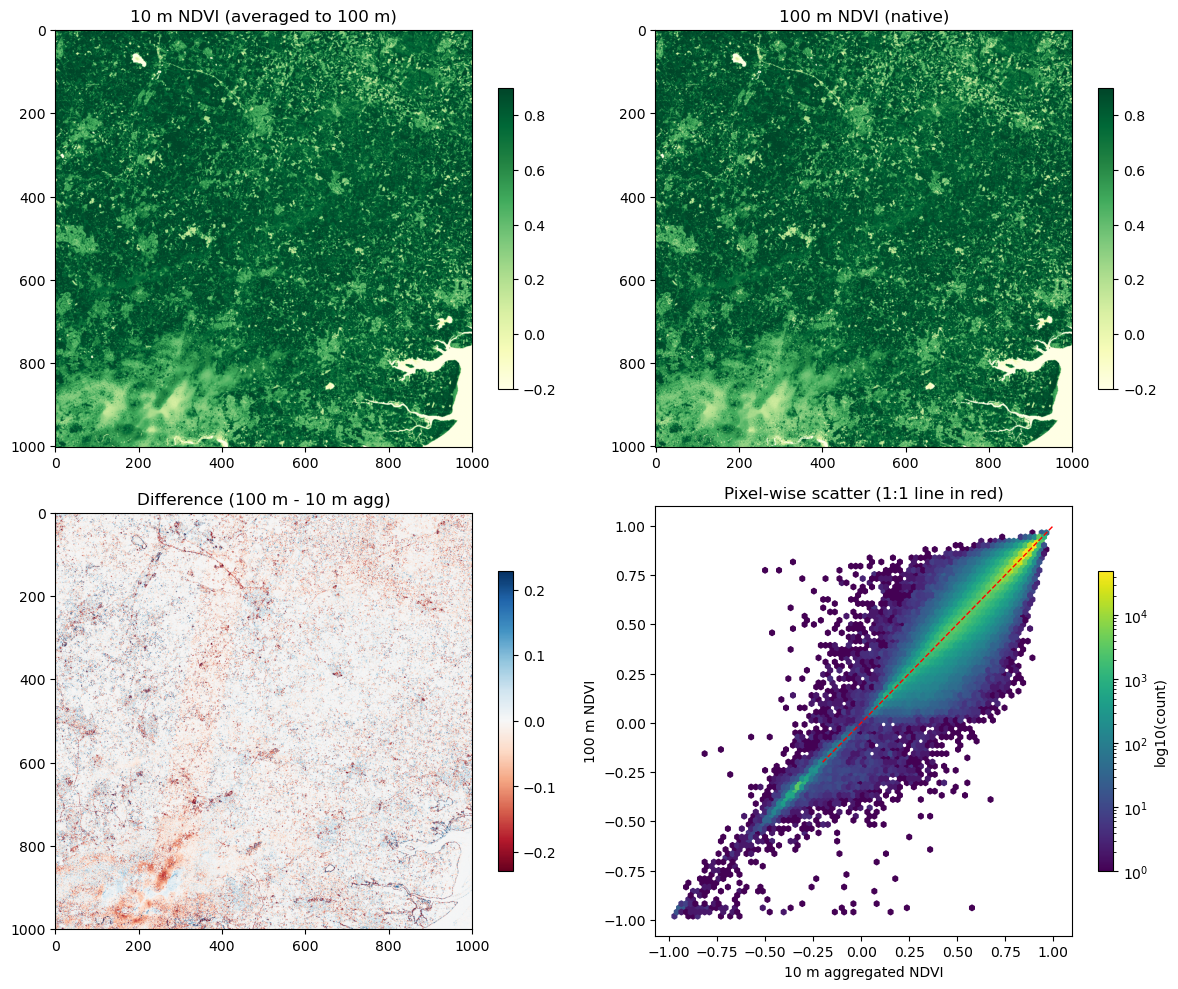

In [43]:
# ---- compare on pixels valid in both ----
valid = np.isfinite(agg_10m) & np.isfinite(ref_arr)
a = agg_10m[valid]   # 10m aggregated
b = ref_arr[valid]   # native 100m
diff = b - a         # 100m minus 10m-aggregated

print(f"\nValid pixels compared: {valid.sum():,} of {valid.size:,}")
print(f"Mean NDVI  10m-agg: {a.mean():.4f} | 100m: {b.mean():.4f}")
print(f"Mean diff (100m - 10m agg): {diff.mean():.4f}")
print(f"MAE:  {np.abs(diff).mean():.4f}")
print(f"RMSE: {np.sqrt((diff**2).mean()):.4f}")
print(f"Pearson r: {np.corrcoef(a, b)[0, 1]:.4f}")
print(f"95th pct |diff|: {np.percentile(np.abs(diff), 95):.4f}")

# ---- plots ----
diff_map = np.where(valid, ref_arr - agg_10m, np.nan)
lim = np.nanpercentile(np.abs(diff_map), 99)

fig, ax = plt.subplots(2, 2, figsize=(12, 10))

im0 = ax[0, 0].imshow(agg_10m, vmin=-0.2, vmax=0.9, cmap="YlGn")
ax[0, 0].set_title("10 m NDVI (averaged to 100 m)")
plt.colorbar(im0, ax=ax[0, 0], shrink=0.7)

im1 = ax[0, 1].imshow(ref_arr, vmin=-0.2, vmax=0.9, cmap="YlGn")
ax[0, 1].set_title("100 m NDVI (native)")
plt.colorbar(im1, ax=ax[0, 1], shrink=0.7)

im2 = ax[1, 0].imshow(diff_map, vmin=-lim, vmax=lim, cmap="RdBu")
ax[1, 0].set_title("Difference (100 m - 10 m agg)")
plt.colorbar(im2, ax=ax[1, 0], shrink=0.7)

hb = ax[1, 1].hexbin(a, b, gridsize=80, bins="log", cmap="viridis")
ax[1, 1].plot([-0.2, 1], [-0.2, 1], "r--", lw=1)
ax[1, 1].set_xlabel("10 m aggregated NDVI")
ax[1, 1].set_ylabel("100 m NDVI")
ax[1, 1].set_title("Pixel-wise scatter (1:1 line in red)")
plt.colorbar(hb, ax=ax[1, 1], shrink=0.7, label="log10(count)")

plt.tight_layout()
plt.show()